# Прогноз покупки в сессии и триггерные коммуникации для eCommerce

`https://github.com/ion04/analytics-rees46-marketplace`

## 1. Продукт

### Что делаем
Имеется сервис, который в режиме реального времени оценивает **вероятность покупки в текущей сессии** по последовательности событий пользователя (`view` → `cart` → `purchase`) и запускает подходящее действие:
- напоминание о брошенной корзине;
- персональная скидка или промокод.

### Для кого
| Сегмент | Роль | Что получает |
|:--|:--|:--|
| Мультикатегорийные интернет-магазины | CRM-/маркетинг-менеджер, продакт | Рост конверсии из корзины в покупку без лишних скидок |
| Команда аналитики магазина | Аналитик, DS | Готовый скоринг и объяснимые факторы поведения |

### Проблема
- Большинство сессий заканчивается **без покупки**, а корзина часто остаётся брошенной.
- Массовые рассылки и скидки «всем подряд» съедают маржу и раздражают клиентов.
- Нет понимания, *кому* и *когда*.

### Гипотеза ценности
> Если по поведению в первых N событиях сессии предсказывать вероятность покупки и вмешиваться только в зоне средней вероятности (покупка возможна, но не гарантирована), то конверсия из корзины (CR cart→purchase) вырастет **не менее чем на 10 %** (относительно) при снижении доли скидочных коммуникаций **не менее чем на 30 %** относительно рассылки «всем».

Пороги 10 % и 30 % — целевые допущения; они фиксируются до эксперимента, а A/B-тест их подтверждает или опровергает.

**Как проверяем:**
1. Офлайн: качество модели (ROC-AUC, PR-AUC, lift по децилям) на временной валидации.
2. Онлайн (в перспективе): A/B-тест «скоринг + триггер» против «рассылка всем» (метрики: CR cart→purchase, выручка на сессию, затраты на скидки).

### Бизнес-модель
- **B2B SaaS**: подписка по объёму обрабатываемых сессий (MAU / события в месяц).
- **Success fee**: небольшой процент от инкрементальной выручки, подтверждённой A/B-тестом.
- **Дополнительно**: платная интеграция с каналами коммуникаций (email, push, мессенджеры).

### Ключевые метрики продукта (подробно — в разделе 4)
| Уровень | Метрика |
|:--|:--|
| Бизнес | CR cart→purchase, выручка на сессию, ROI скидок |
| Продукт | Доля сессий, получивших вмешательство, время ответа скоринга |

### Связь с unit-экономикой (трек Б)
Ценность спасённой корзины — это валовая маржа заказа. LTV/CAC показывает, сколько магазин может тратить на привлечение и удержание пользователя, и тем самым задаёт потолок затрат на скидки и реактивацию.

---

## 2. Данные

### 2.1 Источник
**REES46 «eCommerce behavior data from multi category store»**: обезличенные логи поведенческих событий крупного мультикатегорийного интернет-магазина, опубликованные в рамках инициативы Open CDP.

| Источник | Ссылка |
|:--|:--|
| Оригинальный датасет (Kaggle) | https://www.kaggle.com/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store |

**Версия датасета:** <Version 8>

### 2.2 Лицензия и условия использования
Условия автора датасета (REES46 / Open CDP):
- Свободное использование в **образовательных, научных, исследовательских и демонстрационных** целях.
- При публикации кода, аналитики, книг или учебных материалов **обязательно указывать источник**: ссылки на Kaggle-датасет и на REES46 (см. выше).
- Формальный идентификатор лицензии: `Data files © Original Authors`.

**Данные в репозитории.** Полные CSV в репозиторий не включены: лицензия Kaggle (`Data files © Original Authors`) не даёт права на перепубликацию файлов, к тому же их объём (десятки ГБ) превышает лимит GitHub в 100 МБ на файл. Воспроизведение — по инструкции ниже.

**Как воспроизвести данные:**
```bash
# 1. Установить Kaggle CLI и настроить токен (~/.kaggle/kaggle.json)
pip install kaggle

# 2. Скачать четыре нужных месячных файла в папку data/
# (пакетная загрузка всего датасета добавит другие месяцы, и pipeline.py загрузит их тоже)
for f in 2019-Nov 2019-Dec 2020-Jan 2020-Feb; do
  kaggle datasets download -d mkechinov/ecommerce-behavior-data-from-multi-category-store -f $f.csv -p data/ --unzip
done
```
**Как развернуть инфраструктуру:**
```bash
# Запуск СУБД ClickHouse
docker compose up -d
# Вставка данных в СУБД
python pipeline.py        # все шаги: tables, load, channels, spend, cohorts, views
```

В репозитории хранятся: код, описание схемы.

### 2.3 Объём и период

Значения в таблице проверяются запросом в ячейке под таблицей; в оригинальном датасете есть и другие месячные файлы, используется четыре месяца (ноябрь 2019 – февраль 2020).

| Параметр | Значение |
|:--|:--|
| Период | **4 месяца**: ноябрь 2019 – февраль 2020 |
| Границы времени | `2019-11-01 00:00:00 UTC` – `2020-02-29 23:59:59 UTC` |
| Формат | 4 месячных CSV-файла |
| Число строк | `246 330 463` |
| Уникальных пользователей | `10 723 863` |
| Уникальных сессий | `56 293 798` |
| Уникальных категорий  | `1270` |
| Размер | `3,2 Гб` |


### 2.4 Схема данных
| Поле | Тип / смысл | Комментарий |
|:--|:--|:--|
| `event_time` | datetime (UTC) | Время действия на платформе |
| `event_type` | категориальный | `view` (просмотр), `cart` (в корзину), `purchase` (покупка) |
| `product_id` | идентификатор | Уникальный ID товара в каталоге |
| `category_id` | идентификатор | Уникальный ID категории |
| `category_code` | строка | Иерархия категории (текстовый путь) |
| `brand` | строка | Торговая марка |
| `price` | число | Стоимость товара |
| `user_id` | идентификатор | Уникальный ID покупателя |
| `user_session` | идентификатор | Уникальный ID сессии |

### 2.5 Ограничения датасета
- Данные **обезличены**: нет демографии, канала привлечения, устройства, местоположения.
- Нет информации о **скидках, акциях и коммуникациях**.
- Один магазин → перенос на другие домены требует проверки.
- Пропущенные значения `category_code` (≈ 15,8 %) и `brand` (≈ 13,2 %), см. п. 2.7.
- Нет информации о доставке, возвратах.
- `price` — цена товара в событии, а не фактически уплаченная сумма (скидок и промокодов в данных нет).
- Идентификатор сессии `user_session` задан источником (REES46); правила его формирования нам неизвестны.
- Окно наблюдения — 4 месяца, поэтому LTV считается только за этот срок, а когорта ноября включает пользователей, пришедших до начала окна.
- Канал привлечения и расходы на маркетинг в датасете отсутствуют: для трека Б они **синтетические** (`pipeline.py`, `SEED=26`).

### 2.6 Почему датасет подходит
1. **Прямое соответствие задаче:** есть вся воронка `view → cart → purchase` и идентификатор сессии, значит можно строить целевую переменную «покупка в сессии» и признаки поведения.
2. **Достаточный объём:** миллионы событий и сессий дают статистическую мощность, возможность временной валидации и анализа сегментов.
3. **Реальные данные:** естественные шумы, дисбаланс классов, длинный хвост товаров, а это приближает проект к боевым условиям.
4. **Богатый каталог:** категории, бренды, цены позволяют строить признаки товаров и корзины.
5. **Достаточный период (4 месяца):** можно учесть недельную сезонность и предпраздничный период (ноябрь–декабрь), а затем проверить модель на более позднем периоде (январь–февраль).
6. **Открытая лицензия** для образовательных и исследовательских целей при указании источника.

**Что датасет не покрывает**: причинный эффект скидок и рассылок, признаки устройства и канала, данные о возвратах.

### 2.7 Проверка качества данных

Проверяем пропуски, дубли, границы времени, выбросы и тестовых пользователей. Решения по очистке сведены в таблицу в конце раздела.

Пропуски

In [13]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT
        count() AS total_rows,
        countIf(isNull(user_session)) AS null_user_session,
        countIf(isNull(brand)) AS null_brand,
        countIf(isNull(category_code)) AS null_category_code,
        countIf(empty(event_type)) AS empty_event_type,
        countIf(product_id = 0) AS zero_product_id,
        countIf(user_id = 0) AS zero_user_id
    FROM shop.events
    FORMAT PrettyCompact;
"

   ┌─total_rows─┬─null_user_session─┬─null_brand─┬─null_category_code─┬─empty_event_type─┬─zero_product_id─┬─zero_user_id─┐
1. │  246330463 │                64 │   32456159 │           38961589 │                0 │               0 │            0 │
   └────────────┴───────────────────┴────────────┴────────────────────┴──────────────────┴─────────────────┴──────────────┘


Дубликаты событий

In [15]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT
        sum(c) AS total_rows,
        count() AS unique_events,
        sum(c) - count() AS exact_duplicates
    FROM (
        SELECT count() AS c
        FROM shop.events
        GROUP BY event_type, user_id, event_time, product_id, user_session
    )
    SETTINGS optimize_aggregation_in_order = 1, max_threads = 2,
             max_bytes_before_external_group_by = 2000000000
    FORMAT PrettyCompact;
"

   ┌─total_rows─┬─unique_events─┬─exact_duplicates─┐
1. │  246330463 │     245276299 │          1054164 │ -- 1.05 million
   └────────────┴───────────────┴──────────────────┘


Временные границы

Ожидаем 121 день (ноябрь 30 + декабрь 31 + январь 31 + февраль 29): если `days_with_events` меньше, в данных есть пропущенные дни.

In [16]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT
        min(event_time) AS first_date,
        max(event_time) AS last_date,
        uniqExact(toDate(event_time)) AS days_with_events,
        dateDiff('day', min(event_time), max(event_time)) + 1 AS days_expected
    FROM shop.events
    FORMAT PrettyCompact;
"

   ┌──────────first_date─┬───────────last_date─┬─days_with_events─┬─days_expected─┐
1. │ 2019-11-01 00:00:00 │ 2020-02-29 23:59:59 │              121 │           121 │
   └─────────────────────┴─────────────────────┴──────────────────┴───────────────┘


Выбросы по цене

Кроме квантилей смотрим минимум, максимум, 99,9-й перцентиль и число событий с `price <= 0`.

In [17]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT
        event_type,
        count() AS events,
        countIf(price <= 0) AS price_le_0,
        min(price) AS min_price,
        quantile(0.025)(price) AS q2_5_price,
        median(price) AS median_price,
        quantile(0.975)(price) AS q97_5_price,
        quantile(0.999)(price) AS q99_9_price,
        max(price) AS max_price
    FROM shop.events
    GROUP BY event_type
    FORMAT PrettyCompact;
"

   ┌─event_type─┬────events─┬─price_le_0─┬─min_price─┬─q2_5_price─┬─median_price─┬─q97_5_price─┬─q99_9_price─┬─max_price─┐
1. │ cart       │  11950550 │      10343 │         0 │       9.47 │       168.75 │     1293.74 │     2228.38 │   2574.07 │
2. │ view       │ 230265631 │     504450 │         0 │       7.72 │       162.67 │     1287.01 │     2548.33 │   2574.07 │
3. │ purchase   │   4114282 │          0 │      0.77 │      12.61 │       178.63 │     1286.81 │     2160.68 │   2574.07 │
   └────────────┴───────────┴────────────┴───────────┴────────────┴──────────────┴─────────────┴─────────────┴───────────┘


Порог для исключения тестовых пользователей и ботов

Порог `> 1000 событий на пользователя` должен опираться на распределение, а не на «круглое число». Ячейка показывает перцентили, сколько пользователей попадает под порог и какую долю событий и выручки они дают. Если доля выручки пренебрежимо мала, расчёты витрин из `pipeline.py` (без фильтра) сопоставимы с расчётами ноутбука (с фильтром).

In [18]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    WITH per_user AS (
        SELECT
            user_id,
            count() AS events,
            sumIf(toFloat64(price), event_type = 'purchase' AND price > 0) AS revenue
        FROM shop.events
        GROUP BY user_id
    )
    SELECT
        count() AS users,
        quantile(0.5)(events) AS p50_events,
        quantile(0.99)(events) AS p99_events,
        quantile(0.999)(events) AS p99_9_events,
        countIf(events > 1000) AS flagged_users,
        round(100 * countIf(events > 1000) / count(), 4) AS flagged_users_pct,
        round(100 * sumIf(events, events > 1000) / sum(events), 3) AS flagged_events_pct,
        round(100 * sumIf(revenue, events > 1000) / sum(revenue), 3) AS flagged_revenue_pct
    FROM per_user
    FORMAT PrettyCompact;
"

   ┌────users─┬─p50_events─┬─────────p99_events─┬──────p99_9_events─┬─flagged_users─┬─flagged_users_pct─┬─flagged_events_pct─┬─flagged_revenue_pct─┐
1. │ 10723863 │          4 │ 301.09000000000015 │ 776.7530000000033 │          6171 │            0.0575 │              4.204 │                3.46 │
   └──────────┴────────────┴────────────────────┴───────────────────┴───────────────┴───────────────────┴────────────────────┴─────────────────────┘


#### Выводы по качеству данных и правила очистки

| Проверка | Результат | Решение |
|:--|:--|:--|
| Пропуски | `user_session` — 64 строки (≈ 0,00003 %); `brand` — 32 456 159 (≈ 13,2 %); `category_code` — 38 961 589 (≈ 15,8 %); пустых `event_type`, нулевых `product_id` и `user_id` нет | Строки с `user_session IS NULL` исключаем из сессионных метрик. `brand` и `category_code` оставляем `NULL` и в модели кодируем как «unknown»: на воронку они не влияют |
| Дубли | 1 054 164 строк из 246 330 463 (≈ 0,43 %) по ключу `(event_type, user_id, event_time, product_id, user_session)`; уникальных событий 245 276 299. Прежняя оценка 2,27 млн получена приближённым `uniq` и завышена более чем вдвое | Доля < 1 %, поэтому дубли не удаляем: на метрики пользователей и сессий они не влияют, на выручку влияют не более чем на ≈ 0,4 % |
| Границы времени | `2019-11-01 00:00:00` – `2020-02-29 23:59:59` UTC; дней с событиями: `121` из 121 | Все метрики считаем в UTC; окно наблюдения фиксируем этими границами |
| Выбросы по цене | `price <= 0`: `514 793`; максимум и 99,9-й перцентиль: `2 160,68` | События с `price <= 0` не учитываются в выручке. Верхний хвост не обрезаем, но выручку дополняем медианой чека |
| Аномально активные пользователи (боты, тестовые аккаунты, возможно перекупщики) | Медиана — 4 события на пользователя, p99 ≈ 301, p99,9 ≈ 777. Порог `> 1000` лежит выше p99,9: под него попадают 6 171 пользователь (0,0575 %), они дают 4,2 % событий и 3,46 % выручки; у верхних почти каждое событие в отдельной сессии | Исключаем из когортного анализа и сессионных метрик (разделы 3 и 6): поведение 0,06 % пользователей не характерно для типичного покупателя. Они приносят заметную выручку, поэтому не все они боты. Витрины `pipeline.py` считаются без фильтра: на LTV они влияют не более чем на 3,5 % по выручке и на 0,06 % по числу пользователей, поэтому оставляем как есть, а оговорку фиксируем в разделе 3 |


---

## 3. Определения

Фиксируются здесь и **не меняются** в следующих сдачах. Все определения привязаны к полям датасета (`shop.events`). Время — UTC, неделя — ISO (пн–вс).

| Понятие | Определение |
|:--|:--|
| **Событие** | Строка в `shop.events` с `event_type ∈ {view, cart, purchase}` |
| **Покупка** | Событие `purchase` с `price > 0` |
| **Сессия** | Уникальный `user_session`; строки с `user_session IS NULL` в сессионных метриках не учитываются |
| **Активный пользователь** | Пользователь с **≥ 1 событием любого типа** в периоде. DAU / WAU / MAU — календарные день / неделя / месяц |
| **Активный покупатель** | Пользователь с **≥ 1 покупкой** в периоде |
| **Конверсия сессии** (целевая переменная модели) | Сессия содержит `purchase`: `CR session→purchase = сессии(purchase) / сессии` |
| **Конверсия корзины** (North Star) | `CR cart→purchase = сессии(cart ∧ purchase) / сессии(cart)` |
| **Конверсия пользователя** | `buyers / users`: доля пользователей, совершивших хотя бы одну покупку |
| **Когорта** | Пользователи с одним календарным месяцем **первого события** в датасете (`toStartOfMonth(min(event_time))`) |
| **Удержание месяца k** | Доля пользователей когорты, **активных** в месяце «когорта + k». `k = 0` — месяц привлечения. Вариант «покупательский»: доля **активных покупателей** (для него `k = 0` меньше 100 %) |
| **Правило оттока** | Пользователь **ушёл**, если после его последнего события прошло **≥ 30 дней** без активности. Пользователи, чьё последнее событие позже `2020-01-30`, не классифицируются (окно наблюдения заканчивается `2020-02-29`). `Churn rate = ушедшие / классифицированные` |
| **CAC** | `spend канала / число привлечённых пользователей канала` |
| **LTV** | Накопленная **валовая маржа на пользователя** за окно наблюдения (4 месяца): `выручка × gross_margin_rate / users`. Наблюдаемое значение, не прогноз |
| **LTV/CAC** | `LTV / CAC`; ориентиры: `< 1` — убыточно, `≥ 3` — приемлемо |

**Очистка** (обоснование и числа — в п. 2.7):
- исключаем пользователей с `> 1000` событий (выше p99,9; 6 171 пользователь, 0,06 %) из когортного анализа и сессионных метрик;
- строки с `price <= 0` не учитываются в выручке;
- дубли удаляем только если их доля по точному подсчёту превышает 1 %.

**Оговорки.**
- Датасет начинается `2019-11-01`, поэтому «новые» пользователи ноября включают пришедших раньше: ноябрьская когорта завышена, а её удержание занижено.
- Канал привлечения и расходы **синтетические** (`pipeline.py`, `SEED=26`), поэтому выводы по LTV/CAC сценарные.
- Витрины `pipeline.py` (LTV/CAC) считаются без этого фильтра: исключаемые пользователи дают 3,46 % выручки и 0,06 % пользователей, поэтому LTV может быть завышен не более чем на ≈ 3,5 %.
- `CR cart→purchase` корректна, только если покупки в сессии обычно предваряются событием `cart`; это проверяется ячейкой ниже.


**Проверка определений конверсии.** Если `purchase_without_cart` составляет заметную долю от `sessions_with_purchase`, `CR cart→purchase` занижается или завышается, и в выводах нужно опираться и на `CR session→purchase`.

In [19]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    WITH s AS (
        SELECT
            user_session,
            countIf(event_type = 'cart') AS carts,
            countIf(event_type = 'purchase' AND price > 0) AS purchases
        FROM shop.events
        WHERE user_session IS NOT NULL
        GROUP BY user_session
    )
    SELECT
        count() AS sessions,
        countIf(carts > 0) AS sessions_with_cart,
        countIf(purchases > 0) AS sessions_with_purchase,
        countIf(purchases > 0 AND carts = 0) AS purchase_without_cart,
        round(100 * countIf(carts > 0 AND purchases > 0) / countIf(carts > 0), 2) AS cr_cart_to_purchase_pct,
        round(100 * countIf(purchases > 0) / count(), 2) AS cr_session_to_purchase_pct
    FROM s
    SETTINGS max_bytes_before_external_group_by = 2000000000
    FORMAT PrettyCompact;
"

   ┌─sessions─┬─sessions_with_cart─┬─sessions_with_purchase─┬─purchase_without_cart─┬─cr_cart_to_purchase_pct─┬─cr_session_to_purchase_pct─┐
1. │ 56293798 │            6729404 │                3185855 │                182089 │                   44.64 │                       5.66 │
   └──────────┴────────────────────┴────────────────────────┴───────────────────────┴─────────────────────────┴────────────────────────────┘


---

## 4. Метрики

Метрики выстроены по пирамиде: диагностические метрики объясняют движение North Star, риск-метрика ограничивает, какой ценой оно достигается.

```
            ┌──────────────────────────────┐
            │ North Star: CR cart→purchase │
            └──────────────┬───────────────┘
         ┌─────────────────┴─────────────────┐
┌────────┴─────────────────┐   ┌─────────────┴────────────┐
│ Диагн. 1: качество       │   │ Диагн. 2: охват          │
│ скоринга (Lift@top-decile│   │ вмешательством           │
│ / PR-AUC)                │   │ (coverage)               │
└──────────────────────────┘   └──────────────────────────┘
            ┌──────────────────────────────┐
            │ Риск: доля скидок в марже /  │
            │ ROI скидок                   │
            └──────────────────────────────┘
```

| Роль | Метрика | Формула | Зачем | Какое решение опирается |
|:--|:--|:--|:--|:--|
| **North Star** | CR cart→purchase (сессионная) | `сессии(cart ∧ purchase) / сессии(cart)` | Напрямую отражает ценность продукта: сколько брошенных корзин превращается в покупки | Выкатывать ли «скоринг + триггер» на всех пользователей по итогам A/B-теста |
| **Диагностическая 1** | Lift@top-decile и PR-AUC скоринга | `CR в верхнем дециле скоринга / CR в среднем по выборке` | Если модель плохо ранжирует сессии, вмешательство попадёт «не в тех»; сразу видно, что причина именно в модели | Переобучать модель или менять набор признаков / число N событий |
| **Диагностическая 2** | Охват вмешательством (coverage) | `сессии с вмешательством / сессии с cart` | Показывает, сколько корзин вообще получают шанс на конверсию; слишком мало — потенциал не используется, слишком много — рассылка «всем» | Расширять или сужать «зону средней вероятности» (пороги скоринга) |
| **Риск** | Доля скидок в марже и ROI скидок | `затраты на скидки / валовая маржа`; `ROI = (инкрементальная маржа − скидки) / скидки` | Рост конверсии, купленный скидками, может уничтожать маржу и приучать клиентов ждать скидку | Если `ROI < 1` или доля скидок выше порога, отключить скидки и оставить только напоминания |


---

## 5. Трекинг

Таблица событий: что фиксируем, чем запускается, какие параметры несёт, какую метрику питает и где находится в датасете.

| Событие | Триггер | Параметры | Метрика | Этап пути | Поле датасета |
|:--|:--|:--|:--|:--|:--|
| `view` | Открытие карточки товара | `product_id`, `category_id`, `category_code`, `brand`, `price`, `user_id`, `user_session` | MAU / DAU, признаки скоринга | Просмотр | `event_type = 'view'` + остальные поля схемы |
| `cart` | Добавление товара в корзину | те же | Знаменатель CR cart→purchase, coverage | Корзина | `event_type = 'cart'` |
| `purchase` | Оформление заказа | те же | Числитель CR cart→purchase, выручка, LTV | Покупка | `event_type = 'purchase'`, `price` |
| `user_acquired` | Первое событие пользователя | `user_id`, `channel`, `acquisition_date` | CAC, LTV/CAC, retention по когортам | Привлечение | `min(event_time)`; `channel` — **синтетика**, `shop.user_channels` |
| `session_scored` | Расчёт вероятности после N-го события сессии | `user_session`, `n_events`, `p_purchase`, `model_version` | Lift@top-decile, PR-AUC, coverage | Скоринг | **нет в датасете** (воспроизводится офлайн по `user_session`) |
| `intervention_sent` | `p_purchase` попала в «зону средней вероятности» | `user_session`, тип (`reminder` / `discount`), канал коммуникации, размер скидки | Coverage, доля скидок в марже | Вмешательство | **нет в датасете** |
| `intervention_converted` | Покупка в окне 24 ч после вмешательства | `user_session`, `intervention_id`, сумма заказа | CR cart→purchase, ROI скидок | Результат | **нет в датасете**; сравнивается с `purchase` |

> События `session_scored`, `intervention_*` в публичном датасете отсутствуют (см. п. 2.5), поэтому на текущем этапе они описывают **целевую схему трекинга** продукта. Первые расчёты (раздел 6) используют только `view / cart / purchase` и синтетические каналы.


---

## 6. Первые расчёты (трек Б)

Трек Б: **когортный retention** и **LTV/CAC**. Расчёты выполняются в ClickHouse; код подключения берётся из `pipeline.py`. Перед запуском должны быть выполнены шаги `python pipeline.py` (`load → channels → spend → views`).

### 6.1 Подготовка


In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pipeline import get_client

client = get_client()
BOT_THRESHOLD = 1000   # порог из п. 2.7: > 1000 событий за период = бот / тестовый аккаунт

### 6.2 Когортный retention

Когорта — месяц первого события; удержание — доля пользователей когорты с ≥ 1 событием в месяце `k` (определения в разделе 3). Рассчитываем два варианта: **активность** (любое событие) и **покупательская активность** (≥ 1 `purchase`).


In [23]:
RETENTION_SQL = '''
WITH cohorts AS (
    SELECT user_id, toStartOfMonth(min(event_time)) AS cohort
    FROM shop.events
    GROUP BY user_id
    HAVING count() <= {bot}
),
activity AS (
    SELECT user_id, toStartOfMonth(event_time) AS m
    FROM shop.events
    WHERE {cond}
    GROUP BY user_id, m
)
SELECT
    c.cohort AS cohort,
    dateDiff('month', c.cohort, a.m) AS k,
    uniqExact(a.user_id) AS users
FROM activity AS a
INNER JOIN cohorts AS c USING (user_id)
GROUP BY cohort, k
ORDER BY cohort, k
'''

def cohort_retention(cond):
    df = client.query_df(RETENTION_SQL.format(bot=BOT_THRESHOLD, cond=cond))
    size = client.query_df(
        "SELECT toStartOfMonth(first_event) AS cohort, count() AS size FROM ("
        " SELECT user_id, min(event_time) AS first_event FROM shop.events"
        f" GROUP BY user_id HAVING count() <= {BOT_THRESHOLD}) GROUP BY cohort"
    ).set_index('cohort')['size']
    m = df.pivot(index='cohort', columns='k', values='users')
    ret = m.div(size.reindex(m.index), axis=0)
    ret.insert(0, 'cohort_size', size.reindex(m.index))
    return ret

# 1) активность: любое событие; 2) покупательская активность: только purchase
ret_active = cohort_retention("1")
ret_buy    = cohort_retention("event_type = 'purchase' AND price > 0")

# Для покупательского варианта k=0 — доля купивших в месяц привлечения, а не 100 %
ret_active.index = ret_active.index.strftime('%Y-%m')
ret_buy.index = ret_buy.index.strftime('%Y-%m')
ret_active.style.format({'cohort_size': '{:,.0f}', **{c: '{:.1%}' for c in ret_active.columns[1:]}}, na_rep='')


k,cohort_size,0,1,2,3
cohort,,,,,
2019-11,"3,690,659",100.0%,46.6%,35.6%,31.8%
2019-12,"2,850,444",100.0%,28.1%,21.2%,
2020-01,"2,266,076",100.0%,23.8%,,
2020-02,"1,910,513",100.0%,,,


In [24]:
ret_buy.style.format({'cohort_size': '{:,.0f}', **{c: '{:.1%}' for c in ret_buy.columns[1:]}}, na_rep='')

k,cohort_size,0,1,2,3
cohort,,,,,
2019-11,"3,690,659",11.9%,8.1%,4.5%,4.4%
2019-12,"2,850,444",7.0%,2.5%,2.1%,
2020-01,"2,266,076",5.3%,2.4%,,
2020-02,"1,910,513",5.9%,,,


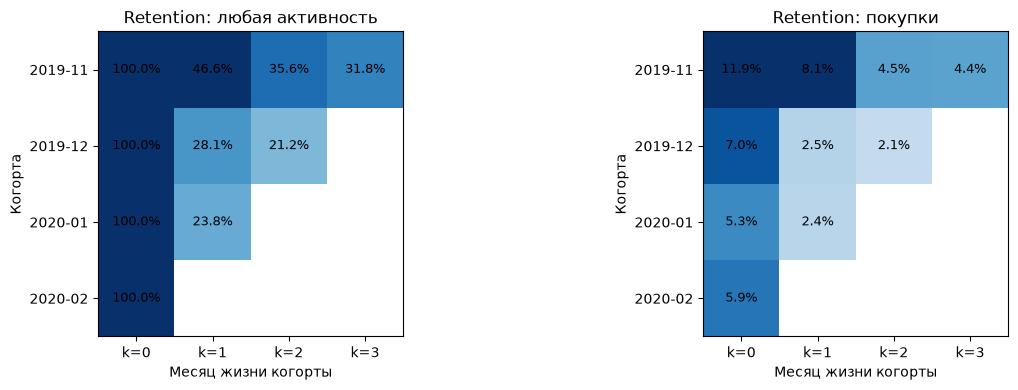

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (title, r) in zip(axes, [('Retention: любая активность', ret_active),
                                  ('Retention: покупки', ret_buy)]):
    data = r.drop(columns='cohort_size')
    im = ax.imshow(data.values.astype(float), cmap='Blues', vmin=0, vmax=max(0.01, np.nanmax(data.values[:, 1:].astype(float)) if data.shape[1] > 1 else 1))
    ax.set_xticks(range(data.shape[1])); ax.set_xticklabels([f'k={c}' for c in data.columns])
    ax.set_yticks(range(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f'{v:.1%}', ha='center', va='center', fontsize=9)
    ax.set_title(title); ax.set_xlabel('Месяц жизни когорты'); ax.set_ylabel('Когорта')
plt.tight_layout(); plt.show()


**Вывод по retention.** Активность (≥ 1 событие в месяце), боты исключены:

| Когорта | Размер | k=1 | k=2 | k=3 |
|:--|--:|--:|--:|--:|
| 2019-11 | 3 690 659 | 46,6 % | 35,6 % | 31,8 % |
| 2019-12 | 2 850 444 | 28,1 % | 21,2 % | |
| 2020-01 | 2 266 076 | 23,8 % | | |
| 2020-02 | 1 910 513 | | | |

- Размеры когорт в сумме дают 10 717 692 пользователя: это 10 723 863 минус 6 171 исключённый (п. 2.7), то есть фильтр применён корректно.
- В месяц после привлечения возвращается лишь 24–28 % пользователей (декабрьская и январская когорты), то есть около трёх из четырёх уходят уже после первого месяца; от k=1 к k=2 кривая выравнивается (28,1 % → 21,2 %).
- Ноябрьская когорта (46,6 %) не сопоставима с остальными: в неё попали пользователи, пришедшие до начала окна (левое цензурирование, см. раздел 3). «Чистые» когорты — декабрь, январь и февраль.
- Покупательский retention (доля когорты с ≥ 1 покупкой в месяце k):

| Когорта | k=0 | k=1 | k=2 | k=3 |
|:--|--:|--:|--:|--:|
| 2019-11 | 11,9 % | 8,1 % | 4,5 % | 4,4 % |
| 2019-12 | 7,0 % | 2,5 % | 2,1 % | |
| 2020-01 | 5,3 % | 2,4 % | | |
| 2020-02 | 5,9 % | | | |

- В месяц привлечения покупает лишь 5,3–7,0 % «чистых» когорт (декабрь–февраль), а в следующем месяце — около 2,5 %. При этом активны 24–28 %: возвращается много пользователей, но покупает примерно каждый десятый из вернувшихся (2,5 % против 28,1 % у декабря). Основная масса приходит смотреть, а не покупать.
- Решение: большая часть пользователей теряется после первого месяца, а вернувшиеся редко покупают. Поэтому триггер должен срабатывать на брошенной корзине внутри сессии и в первые дни после неё, а не через месяц. Это подтверждает фокус продукта на конверсии в сессии (CR cart→purchase), а не на реактивации «спящих» пользователей.
- Оговорка: ноябрьская когорта (11,9 % покупателей в k=0) завышена возвращающимися клиентами и Чёрной пятницей (29.11.2019), поэтому для ориентиров берём декабрь–февраль.

### 6.3 LTV/CAC по каналам

Выручка берётся из реальных покупок, **расходы и маржинальность синтетические** (`shop.channel_spend`, сценарное допущение: маркетинг ≈ 8,75 % выручки). Расчёт — готовая витрина `shop.v_channel_unit_economics`.


In [28]:
def show(df, fmt):
    out = df.astype(object).copy()
    for col, f in fmt.items():
        out[col] = df[col].map(lambda v, f=f: '' if pd.isna(v) else f.format(v))
    return out

In [29]:
ltv = client.query_df('''
    SELECT channel, users, spend, cac, revenue, gross_margin, ltv, ltv_cac,
           conversion_to_purchase, profit
    FROM shop.v_channel_unit_economics
    ORDER BY ltv_cac DESC
''')
show(ltv, {
    'users': '{:,.0f}', 'spend': '{:,.0f}', 'cac': '{:.2f}', 'revenue': '{:,.0f}',
    'gross_margin': '{:,.0f}', 'ltv': '{:.2f}', 'ltv_cac': '{:.2f}',
    'conversion_to_purchase': '{:.1%}', 'profit': '{:,.0f}',
})


,channel,users,spend,cac,revenue,gross_margin,ltv,ltv_cac,conversion_to_purchase,profit
0,email,"1,199,923","5,691,922",4.74,"249,408,707","69,666,242",58.06,12.24,21.5%,"63,974,319"
1,organic_search,"2,276,105","16,433,646",7.22,"380,047,821","113,792,913",49.99,6.92,17.0%,"97,359,268"
2,referral,"729,156","11,253,674",15.43,"253,317,923","63,180,630",86.65,5.61,35.4%,"51,926,957"
3,paid_search,"3,558,301","45,104,408",12.68,"254,652,252","56,187,231",15.79,1.25,7.3%,"11,082,823"
4,social,"2,960,378","33,020,198",11.15,"124,156,307","24,886,773",8.41,0.75,4.3%,"-8,133,426"


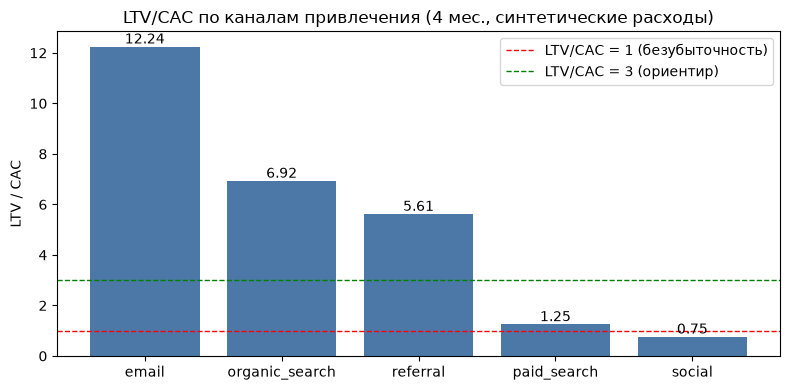

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(ltv['channel'], ltv['ltv_cac'], color='#4C78A8')
ax.axhline(1, color='red', ls='--', lw=1, label='LTV/CAC = 1 (безубыточность)')
ax.axhline(3, color='green', ls='--', lw=1, label='LTV/CAC = 3 (ориентир)')
ax.bar_label(bars, fmt='%.2f')
ax.set_ylabel('LTV / CAC'); ax.set_title('LTV/CAC по каналам привлечения (4 мес., синтетические расходы)')
ax.legend(); plt.tight_layout(); plt.show()


**Вывод по LTV/CAC** (4 месяца, синтетические расходы и каналы):

| Канал | LTV/CAC | Оценка |
|:--|--:|:--|
| email | 12,24 | сильно выше ориентира 3 |
| organic_search | 6,92 | выше ориентира |
| referral | 5,61 | выше ориентира |
| paid_search | 1,25 | едва окупается |
| social | 0,75 | убыточен: валовая маржа не покрывает расходы |

- Три канала (email, organic_search, referral) окупаются с большим запасом, два платных (paid_search, social) — на грани или ниже безубыточности. Для social `profit < 0`.
- **Оговорка.** Этот порядок во многом задан сценарием синтетики, а не данными магазина: каналы назначены по правилу «платные каналы приводят больше не покупателей», а доли бюджета и маржа заданы в `pipeline.py`. Поэтому результат демонстрирует метод расчёта и чувствительность к допущениям, а не реальную экономику каналов. LTV наблюдаемый за 4 месяца, не прогнозный.
- Решение (при условии, что реальная атрибуция даст похожую картину): сокращать или пересматривать social, оптимизировать paid_search до порога LTV/CAC ≥ 3, а высвободившийся бюджет проверять на email и referral, помня, что у небольших каналов отдача падает при масштабировании.
- Связь с продуктом: при LTV/CAC выше 3 у магазина есть запас, чтобы платить за вмешательства (напоминания, скидки) на брошенных корзинах; потолок затрат на скидку определяется маржой заказа (раздел 1).

---

## 7. Этика

| Вопрос | Комментарий |
|:--|:--|
| **Цель** | Оценить удержание и окупаемость каналов (LTV/CAC) и показать, на каких пользователей и в какой момент имеет смысл направлять триггерные коммуникации. Цель — не профилирование людей, а снижение лишних скидок и рассылок |
| **Согласие** | Данные обезличены и опубликованы владельцем (REES46) для исследовательских и образовательных целей; прямых идентификаторов (имя, email, адрес) нет. В реальном внедрении нужно согласие на обработку и на коммуникации, а также простой отказ от рассылок (opt-out) |
| **Специальные категории** | Демографии, здоровья и других специальных категорий в данных нет. Но `category_code` может косвенно указывать на чувствительные покупки (например, медицинские товары), поэтому такие категории не используем для таргетинга скидок |
| **Передача третьим лицам** | Данные не передаются: ClickHouse и Superset запускаются локально в Docker, внешним сервисам данные не отправляются. Секреты (`.env`) в репозиторий не попадают |
| **Хранение и удаление** | Полные данные лежат только локально (`data/`, `clk_data/`) и исключены из Git (`.gitignore`). Удаление: остановить контейнеры и удалить `clk_data/` и `data/`. В реальном внедрении нужен срок хранения и процедура удаления данных пользователя по запросу |
| **Происхождение и лицензия** | REES46 / Open CDP, Kaggle; источник указан в разделе 2, лицензия — `Data files © Original Authors`, файлы не перепубликуются |
| **Риски и ограничения** | (1) Повторная идентификация по `user_id` и поведению: деанонимизацию не предпринимаем. (2) Персональные скидки могут быть несправедливыми к группам пользователей: нужен контроль критериев и прозрачность. (3) Канал и расходы в треке Б **синтетические**, поэтому выводы по LTV/CAC нельзя выдавать за реальную экономику магазина. (4) Частые напоминания раздражают клиентов: нужен лимит частоты |


---

## 8. Критерии успеха

Целевые значения к финалу проекта. Базовые значения взяты из расчётов выше; цели — допущения, фиксируемые до эксперимента.

| Метрика | Базовое значение | Целевое значение | Как проверяем |
|:--|:--|:--|:--|
| **CR cart→purchase** (North Star) | 44,64 % (сессии с `cart`, раздел 3) | ≥ 49,1 % (+10 % относительно) | A/B-тест «скоринг + триггер» против «рассылка всем»: рандомизация по `user_id`, единица анализа — сессия с `cart`, z-тест для долей, α = 0,05, мощность 0,8 |
| **Retention месяца 1** (трек Б) | активность 23,8–28,1 %, покупки 2,4–2,5 % (когорты декабрь и январь, раздел 6.2) | активность ≥ 30 %, покупки ≥ 3,0 % | Те же SQL по новым когортам после запуска, сравнение с контрольной группой (`v_cohort_retention`) |
| **LTV/CAC** (трек Б) | см. ячейку ниже; по каналам от 0,75 (social) до 12,24 (email) | общий LTV/CAC ≥ 3 и **ни один канал не ниже 1** | Пересчёт `v_channel_unit_economics` после перераспределения бюджета; на реальных, а не синтетических расходах |
| *Guardrail:* доля скидочных коммуникаций | 100 % сессий с `cart` при рассылке «всем» | ≤ 70 % (−30 %) при ROI скидок ≥ 1 | Логи `intervention_sent` / `intervention_converted` (раздел 5) |

Офлайн-критерий качества модели (до A/B): Lift@top-decile ≥ 3 и PR-AUC выше базовой доли покупок в сессии (5,66 %) на временной валидации (обучение — ноябрь–январь, тест — февраль).


---

## 9. Репозиторий

Что есть в репозитории и где искать:

| Файл | Назначение |
|:--|:--|
| `README.md` | Задача, откуда данные, как запустить, что получилось |
| `requirements.txt` | Зависимости Python |
| `.gitignore` | Исключает данные (`*.csv`, `data/`, `clk_data/`), секреты (`.env`) и служебные папки |
| `.env.example` | Шаблон настроек без секретов (скопировать в `.env`) |
| `docker-compose.yaml` | ClickHouse (и Superset) |
| `pipeline.py` | Загрузка данных, синтетические каналы и расходы, когорты, витрины |
| `intro.ipynb` | Этот ноутбук |

Данные в репозитории **не хранятся** (лицензия и объём, см. п. 2.2); воспроизведение — по инструкции в п. 2.2 и в `README.md`.
